# The trinomial stencil $f = 1 + x + x^2 + y$

**Kernel, fractal subsystem symmetries, membranes, and restricted mobility.**

Companion notebook to [`docs/2d_fraction_working_note.md`](../docs/2d_fraction_working_note.md),
which is itself a companion to the primer [`docs/main_2.pdf`](../docs/main_2.pdf)
(*From Stencils to Group Rings*).

Every claim in the working note is re-derived here from scratch. Most reproduce exactly.
Three are corrected, and two open threads are closed. Section 9 collects those.

**The dictionary** (primer §1), used throughout:

| lattice | algebra |
|---|---|
| site at offset $(d_1,d_2)$ | monomial $x^{d_1}y^{d_2}$ |
| stencil | polynomial $f(x,y)$ |
| spin configuration | polynomial $t(x,y)$ |
| roll stencil + sum mod 2 | multiplication $f\cdot t$ |
| periodic boundaries | $x^{L_x}=1,\; y^{L_y}=1$ |
| the matrix $A$ | "multiply by $f$" in $R_L=\mathbb F_2[x,y]/(x^{L_x}-1,y^{L_y}-1)$ |
| $N_c$ | $\dim\ker A=\dim\operatorname{Ann}(f)$, and $\mathrm{GSD}=2^{N_c}$ |

The same stencil is registered as `"trinomial"` in
[`notebooks/degeneracy_sweep.ipynb`](degeneracy_sweep.ipynb), so the sweep/validation
machinery there covers it too.

## 0. Setup

In [1]:
import sys, itertools
import numpy as np
import matplotlib.pyplot as plt
from math import gcd, log2, sqrt

sys.path.insert(0, "../scripts")
import nc_sweep as ns          # reuse the repo's stencil -> matrix builder

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})


# --------------------------------------------------------------- GF(2) core
def build_matrix(shifts, Lx, Ly):
    """Column k = the stencil stamped down at site k.

    Identical to scripts/nc_sweep.build_matrix at p=2, i.e. the matrix of
    "multiply by f" in F_2[x,y]/(x^Lx - 1, y^Ly - 1).
    """
    return ns.build_matrix(shifts, Lx, Ly, 2).astype(np.uint8)


def rref(M):
    """Row-reduced echelon form over GF(2). Returns (R, pivot_columns)."""
    M = (M.copy() % 2).astype(np.uint8)
    rows, cols = M.shape
    pivots, r = [], 0
    for c in range(cols):
        nz = np.flatnonzero(M[r:, c])
        if nz.size == 0:
            continue
        pr = r + nz[0]
        if pr != r:
            M[[r, pr]] = M[[pr, r]]
        sel = M[:, c].astype(bool).copy()
        sel[r] = False
        M[sel] ^= M[r]
        pivots.append(c)
        r += 1
        if r == rows:
            break
    return M, pivots


def nullspace(A):
    """Basis for {t : A t = 0} over GF(2), one basis vector per ROW."""
    R, pivots = rref(A)
    cols = A.shape[1]
    free = [c for c in range(cols) if c not in pivots]
    B = np.zeros((len(free), cols), dtype=np.uint8)
    for j, f in enumerate(free):
        B[j, f] = 1
        for i, pc in enumerate(pivots):
            B[j, pc] = R[i, f]
    return B


def Nc(shifts, Lx, Ly):
    """dim ker A, via the repo bit-packed rank routine (fast for sweeps)."""
    return Lx * Ly - ns.rank_gf2(ns.build_matrix(shifts, Lx, Ly, 2))


# --------------------------------------------------------------- the players
TRI = [(0, 0), (0, 1), (0, 2), (1, 0)]          # f = 1 + x + x^2 + y
TRI_T = [(-d2, -d1) for (d2, d1) in TRI]        # reversed stencil -> A^T
NM = [(0, 0), (0, 1), (1, 0)]                   # Newman-Moore, f = 1 + x + y
DW = [(0, 0), (0, 1)]                           # control, f = 1 + x (domain wall)
HAAH_Z = ns.HAAH_Z_SHIFTS                       # f = 1+x+x^2+y+xy+y^2

print("trinomial shifts (d_row, d_col):", TRI)
print("reversed                       :", TRI_T)

trinomial shifts (d_row, d_col): [(0, 0), (0, 1), (0, 2), (1, 0)]
reversed                       : [(0, 0), (0, -1), (0, -2), (-1, 0)]


In [2]:
# Sanity: the reversed stencil really does build A^T, and the primer reference
# numbers for haah_z come out.
A  = build_matrix(TRI, 12, 12)
AT = build_matrix(TRI_T, 12, 12)
assert (A.T == AT).all(), "reversed stencil is not the transpose"
print("reversed stencil == transpose:", True)
print("N_c(haah_z, 32, 32) =", Nc(HAAH_Z, 32, 32), " (primer: 63)")
print("N_c(haah_z, 15, 15) =", Nc(HAAH_Z, 15, 15), " (primer: 27)")

reversed stencil == transpose: True
N_c(haah_z, 32, 32) = 63  (primer: 63)
N_c(haah_z, 15, 15) = 27  (primer: 27)


## 1. The stencil and its Hamiltonian

The working note designs the stencil by the inverse recipe of its §2: pick the
row-to-row recurrence first, read off the stencil second.

$$t_{r+1}=(1+x+x^2)\,t_r \qquad\Longleftrightarrow\qquad f(x,y)=1+x+x^2+y$$

Shifts (row, col): $(0,0),(0,1),(0,2),(1,0)$. Reading these as primer eq. (6) gives a
quartic, frustration-free classical spin model on the torus:

$$H=-J\sum_{i,j}\sigma_{i,j}\,\sigma_{i,j+1}\,\sigma_{i,j+2}\,\sigma_{i+1,j}$$

A configuration is a ground state iff every one of those products is $+1$, i.e. iff
$At=0$. So $\text{ground states}=\ker A$ and $\mathrm{GSD}=2^{N_c}$.

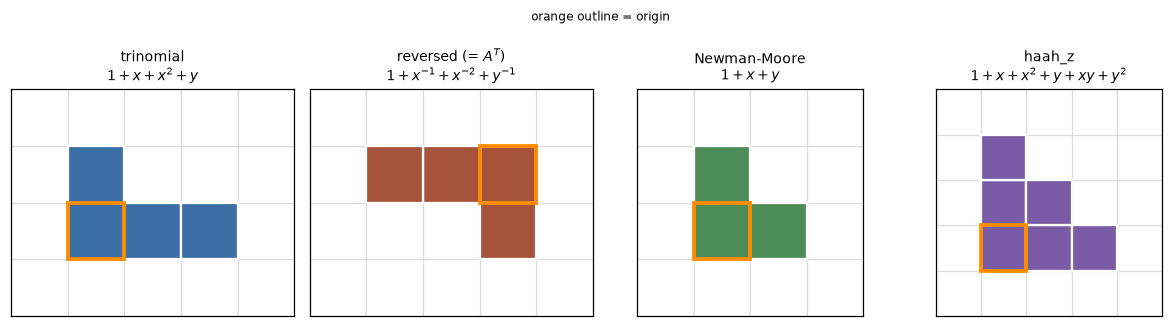

In [3]:
def draw_stencil(ax, shifts, title, color="#3b6ea5"):
    rs = [s[0] for s in shifts]; cs = [s[1] for s in shifts]
    r0, r1, c0, c1 = min(rs) - 1, max(rs) + 1, min(cs) - 1, max(cs) + 1
    for r in range(r0, r1 + 1):
        for c in range(c0, c1 + 1):
            ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, fc="white", ec="#dddddd", lw=.8))
    for (r, c) in shifts:
        ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, fc=color, ec="white", lw=1.5))
    ax.add_patch(plt.Rectangle((-.5, -.5), 1, 1, fc="none", ec="darkorange", lw=2.5))
    ax.set_xlim(c0 - .5, c1 + .5); ax.set_ylim(r0 - .5, r1 + .5)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=9)

fig, ax = plt.subplots(1, 4, figsize=(11, 2.8))
draw_stencil(ax[0], TRI,    "trinomial\n$1+x+x^2+y$")
draw_stencil(ax[1], TRI_T,  "reversed (= $A^T$)\n$1+x^{-1}+x^{-2}+y^{-1}$", "#a5533b")
draw_stencil(ax[2], NM,     "Newman-Moore\n$1+x+y$", "#4d8c57")
draw_stencil(ax[3], HAAH_Z, "haah_z\n$1+x+x^2+y+xy+y^2$", "#7a5ba5")
fig.suptitle("orange outline = origin", y=1.04, fontsize=8)
plt.tight_layout(); plt.show()

## 2. $N_c=\dim\ker A$ — reproducing the working note's table

The note's table for $L_x=L_y=L$. Brute-force Gaussian elimination over GF(2).

In [4]:
Ls = [15, 16, 17, 31, 32, 33, 63, 64, 65]
note_table = {15: 13, 16: 16, 17: 1, 31: 31, 32: 32, 33: 1, 63: 61, 64: 64, 65: 1}
got = {L: Nc(TRI, L, L) for L in Ls}

print(" L      :", "".join(f"{L:6d}" for L in Ls))
print(" note   :", "".join(f"{note_table[L]:6d}" for L in Ls))
print(" this nb:", "".join(f"{got[L]:6d}" for L in Ls))
print("\nagree:", got == note_table)

 L      :     15    16    17    31    32    33    63    64    65
 note   :     13    16     1    31    32     1    61    64     1
 this nb:     13    16     1    31    32     1    61    64     1

agree: True


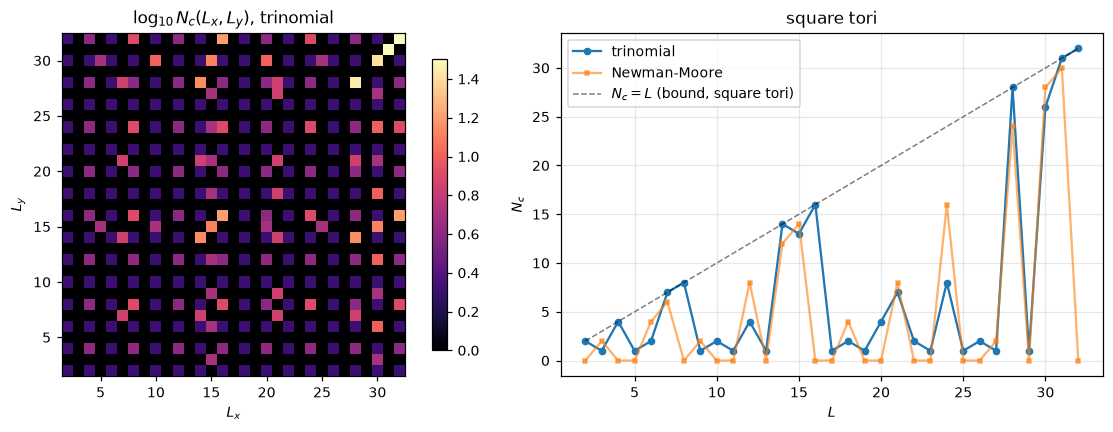

N_c <= Lx           on the whole grid: True
N_c <= min(Lx,Ly)   on the whole grid: False   counterexamples (Lx,Ly,N_c): [(15, 3, 5), (30, 3, 5), (30, 6, 10)]
asymmetry N_c(Lx,Ly) vs N_c(Ly,Lx): [(5, 15, 5, 1), (15, 3, 5, 1), (4, 12, 4, 4)]


In [5]:
# the full picture: N_c(Lx, Ly) on a rectangular grid, and N_c(L, L)
LS = list(range(2, 33))
grid = np.array([[Nc(TRI, lx, ly) for lx in LS] for ly in LS])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
im = ax[0].imshow(np.log10(grid), cmap="magma", origin="lower",
                  extent=[LS[0] - .5, LS[-1] + .5, LS[0] - .5, LS[-1] + .5])
ax[0].set_xlabel("$L_x$"); ax[0].set_ylabel("$L_y$")
ax[0].set_title("$\\log_{10}N_c(L_x,L_y)$, trinomial")
fig.colorbar(im, ax=ax[0], shrink=.85)

diag = [Nc(TRI, L, L) for L in LS]
ax[1].plot(LS, diag, "o-", ms=4, label="trinomial")
ax[1].plot(LS, [Nc(NM, L, L) for L in LS], "s-", ms=3, alpha=.6, label="Newman-Moore")
ax[1].plot(LS, LS, "k--", lw=1, alpha=.5, label="$N_c=L$ (bound, square tori)")
ax[1].set_xlabel("$L$"); ax[1].set_ylabel("$N_c$")
ax[1].set_title("square tori"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

# The bound is ASYMMETRIC: f has degree 2 in x but only degree 1 in y, so
# N_c(Lx,Ly) != N_c(Ly,Lx) in general and the bound is N_c <= Lx, not min(Lx,Ly).
over_lx = [(LS[j], LS[i], int(grid[i, j]))
           for i in range(len(LS)) for j in range(len(LS)) if grid[i, j] > LS[j]]
over_min = [(LS[j], LS[i], int(grid[i, j]))
            for i in range(len(LS)) for j in range(len(LS)) if grid[i, j] > min(LS[j], LS[i])]
print("N_c <= Lx           on the whole grid:", not over_lx)
print("N_c <= min(Lx,Ly)   on the whole grid:", not over_min,
      "  counterexamples (Lx,Ly,N_c):", over_min[:3])
print("asymmetry N_c(Lx,Ly) vs N_c(Ly,Lx):",
      [(a, b, Nc(TRI, a, b), Nc(TRI, b, a)) for a, b in [(5, 15), (15, 3), (4, 12)]])

### The UV/IR signature

The bright cells sit on the $v_2(L_x)=v_2(L_y)$ families, exactly as for `haah_z`
(primer Fig. 3). The note's summary — *extensive growth at powers of 2, collapsing to
$N_c=1$ at $L=2^k+1$* — reproduces, with one wording fix: the growth is **linear**
in $L$, hence *sub-extensive* (extensive would be $\propto L^2$ = the number of sites).
The primer is careful about this distinction in §12, and it matters:
sub-extensive-but-unbounded is precisely the fracton signature.

In [6]:
for L in (2, 4, 8, 16, 32, 64, 128):
    print(f"  N_c({L:3d},{L:3d}) = {Nc(TRI, L, L):4d}    "
          f"N_c({L:3d},{L + 1:3d}) = {Nc(TRI, L, L + 1):4d}")

  N_c(  2,  2) =    2    N_c(  2,  3) =    1
  N_c(  4,  4) =    4    N_c(  4,  5) =    1
  N_c(  8,  8) =    8    N_c(  8,  9) =    1
  N_c( 16, 16) =   16    N_c( 16, 17) =    1
  N_c( 32, 32) =   32    N_c( 32, 33) =    1


  N_c( 64, 64) =   64    N_c( 64, 65) =    1


  N_c(128,128) =  128    N_c(128,129) =    1


## 3. The closed form — with a correction

The note gives (its §2):

$$N_c(L_x,L_y)=\min(2^a,2^b)\cdot\deg\gcd_{\mathbb F_2}\big(y^{m_y}+1,\ g(x)^{m_x}+1\big),
\qquad L_x=2^am_x,\; L_y=2^bm_y$$

**The exponent on $g$ is wrong: it should be $m_y$, not $m_x$.** Derivation, following
primer §17 (Newman-Moore, no singular point to resolve, so everything stays in
$\mathbb F_2$): the curve $f=0$ means $\eta=g(\zeta)$ with $g=1+x+x^2$. A contributing
point needs $\zeta\in\mu_{m_x}$ *and* $\eta\in\mu_{m_y}$, i.e. $g(\zeta)^{m_y}=1$.
Both are polynomial conditions on the single variable $\zeta$, so

$$\boxed{\;N_c(L_x,L_y)=\min(2^a,2^b)\cdot N(m_x,m_y),\qquad
N(m_x,m_y)=\deg\gcd_{\mathbb F_2[x]}\big(x^{m_x}+1,\ g(x)^{m_y}+1\big)\;}$$

equivalently $N=\#\{\zeta\in\mu_{m_x}:g(\zeta)\in\mu_{m_y}\}$.

The note's version writes $y^{m_y}+1$ against $g(x)^{m_x}+1$ — two different variables,
and the two exponents swapped. On **square** tori $m_x=m_y$ and the slip is invisible,
which is why the note's table is unaffected. It only bites on rectangles.

In [7]:
# --- GF(2) univariate polynomials as integer bitmasks -----------------------
def pmul(a, b):
    r = 0
    while b:
        if b & 1:
            r ^= a
        a <<= 1; b >>= 1
    return r

def pdeg(a):
    return a.bit_length() - 1

def pmod(a, b):
    db = pdeg(b)
    while a and pdeg(a) >= db:
        a ^= b << (pdeg(a) - db)
    return a

def pgcd(a, b):
    while b:
        a, b = b, pmod(a, b)
    return a

def ppow(base, e, mod):
    r, base = 1, pmod(base, mod)
    while e:
        if e & 1:
            r = pmod(pmul(r, base), mod)
        base = pmod(pmul(base, base), mod)
        e >>= 1
    return r

G = 0b111        # g(x) = 1 + x + x^2

def v2(L):
    a = 0
    while L % 2 == 0:
        L //= 2; a += 1
    return a, L

def N_odd(mx, my):
    """Count zeta in mu_mx with g(zeta) in mu_my."""
    M = (1 << mx) | 1                       # x^mx + 1
    return pdeg(pgcd(M, ppow(G, my, M) ^ 1))

def Nc_closed(Lx, Ly):
    a, mx = v2(Lx); b, my = v2(Ly)
    return min(2 ** a, 2 ** b) * N_odd(mx, my)

def Nc_closed_as_written(Lx, Ly):
    """The note version, with the exponents swapped."""
    a, mx = v2(Lx); b, my = v2(Ly)
    M = (1 << mx) | 1
    return min(2 ** a, 2 ** b) * pdeg(pgcd(M, ppow(G, mx, M) ^ 1))

In [8]:
LMAX = 24
ok_fixed = ok_note = 0
mismatch = []
for lx in range(2, LMAX + 1):
    for ly in range(2, LMAX + 1):
        t = Nc(TRI, lx, ly)
        ok_fixed += (Nc_closed(lx, ly) == t)
        ok_note += (Nc_closed_as_written(lx, ly) == t)
        if Nc_closed_as_written(lx, ly) != t and len(mismatch) < 5:
            mismatch.append((lx, ly, t, Nc_closed_as_written(lx, ly)))

total = (LMAX - 1) ** 2
print(f"full grid 2 <= Lx,Ly <= {LMAX}   ({total} lattices)")
print(f"  corrected form  g(x)^m_y : {ok_fixed}/{total}")
print(f"  note as written g(x)^m_x : {ok_note}/{total}")
print("\nfirst mismatches (Lx, Ly, brute force, note formula):")
for m in mismatch:
    print("   ", m)

print("\nclosed form at sizes brute force cannot touch:")
for L in (85, 91, 127, 255, 341, 1023, 4095):
    print(f"   N_c({L},{L}) = {Nc_closed(L, L)}")

full grid 2 <= Lx,Ly <= 24   (529 lattices)
  corrected form  g(x)^m_y : 529/529
  note as written g(x)^m_x : 446/529

first mismatches (Lx, Ly, brute force, note formula):
    (5, 15, 5, 1)
    (7, 2, 1, 7)
    (7, 3, 1, 7)
    (7, 4, 1, 7)
    (7, 5, 1, 7)

closed form at sizes brute force cannot touch:
   N_c(85,85) = 17
   N_c(91,91) = 7
   N_c(127,127) = 127
   N_c(255,255) = 253
   N_c(341,341) = 141
   N_c(1023,1023) = 1021
   N_c(4095,4095) = 4093


### The analog of the "$3\mid\gcd(m_x,m_y)$" criterion

The note's §6 asks for this. For `haah_z` the primer (§16) finds that $3\mid\gcd$
*raises* the degeneracy, because $\omega\in\mu_m$ then lands on a branch of the split
conic. Here the criterion **inverts**, for a clean reason:

$$g(x)=1+x+x^2=\Phi_3(x)$$

so the roots of $g$ are exactly $\omega,\omega^2$. If $3\mid m_x$ those two roots lie in
$\mu_{m_x}$, but they give $g(\zeta)=0\notin\mu_{m_y}$ — they are *excluded*. So
$3\mid m_x$ **removes two points** instead of adding them.

The maximal family is instead $m=2^k-1$, where $\mu_m=\mathbb F_{2^k}^\times$ is the whole
multiplicative group, so $g(\zeta)\in\mu_m$ automatically for every non-root $\zeta$:

$$N(m,m)=m-2\cdot[\,3\mid m\,]=m-2\cdot[\,k\text{ even}\,],\qquad m=2^k-1$$

giving $N_c\approx L$ — half of `haah_z`'s $\approx 2L$, exactly what one expects from
**one** branch rather than the two conjugate lines of the split conic.

In [9]:
print("m = 2^k - 1 family:      N(m,m)  vs  m - 2*[k even]")
for k in range(2, 12):
    m = 2 ** k - 1
    pred = m - 2 * (k % 2 == 0)
    got_ = N_odd(m, m)
    print(f"   k={k:2d}  m={m:6d}   N={got_:6d}   pred={pred:6d}   "
          f"{'ok' if got_ == pred else 'MISMATCH'}")

print("\nodd m <= 200 with N(m,m) > 1  (the 'anomalously large' set):")
big = [(m, N_odd(m, m)) for m in range(1, 201, 2) if N_odd(m, m) > 1]
print("   ", [m for m, _ in big])
print("\n   m : N(m,m) : ord_m(2)   (every one of these has m | 2^ord - 1)")
for m, n in big[:14]:
    o, v = 1, 2 % m
    while v != 1:
        v = v * 2 % m; o += 1
    print(f"   {m:4d} : {n:4d} : {o:4d}      m | 2^ord-1 : {(2 ** o - 1) % m == 0}")

print("\ncontrast with haah_z, where 3 | m RAISES N:")
print("   trinomial N(15,15) =", N_odd(15, 15), " = 15 - 2   (3 | 15 removes omega, omega^2)")
print("   trinomial N(31,31) =", N_odd(31, 31), " = 31       (3 does not divide 31)")

m = 2^k - 1 family:      N(m,m)  vs  m - 2*[k even]
   k= 2  m=     3   N=     1   pred=     1   ok
   k= 3  m=     7   N=     7   pred=     7   ok
   k= 4  m=    15   N=    13   pred=    13   ok
   k= 5  m=    31   N=    31   pred=    31   ok
   k= 6  m=    63   N=    61   pred=    61   ok
   k= 7  m=   127   N=   127   pred=   127   ok
   k= 8  m=   255   N=   253   pred=   253   ok
   k= 9  m=   511   N=   511   pred=   511   ok
   k=10  m=  1023   N=  1021   pred=  1021   ok
   k=11  m=  2047   N=  2047   pred=  2047   ok

odd m <= 200 with N(m,m) > 1  (the 'anomalously large' set):
    [7, 15, 21, 31, 35, 45, 49, 51, 63, 75, 77, 85, 91, 93, 105, 119, 127, 133, 135, 147, 153, 155, 161, 165, 175, 189, 195]

   m : N(m,m) : ord_m(2)   (every one of these has m | 2^ord - 1)
      7 :    7 :    3      m | 2^ord-1 : True
     15 :   13 :    4      m | 2^ord-1 : True
     21 :    7 :    6      m | 2^ord-1 : True
     31 :   31 :    5      m | 2^ord-1 : True
     35 :    7 :   12      m |

## 4. The kernel: ground states, and the symmetries

Primer §8. Two *different* kernels, same dimension:

* **Ground states** $=\ker A$ — configurations with every Hamiltonian term satisfied.
* **Flip symmetries** $=\ker A^{\!\top}$ — patterns $u$ such that flipping the spins on
  $\operatorname{supp}(u)$ leaves *every* term of $H$ invariant. $A^{\!\top}$ is the
  **reversed** stencil $(0,0),(0,-1),(0,-2),(-1,0)$.

They coincide as sets only for a symmetric stencil; this one is not symmetric, so they
genuinely differ as subspaces. $\operatorname{rank}A=\operatorname{rank}A^{\!\top}$ makes
them equidimensional, so counting ground states and counting symmetries is the same count
— which is the content of primer §8 and the reason $\mathrm{GSD}=2^{N_c}$.

In [10]:
L = 16
A  = build_matrix(TRI, L, L)
AT = build_matrix(TRI_T, L, L)

K_gs  = nullspace(A)      # ground states
K_sym = nullspace(AT)     # flip symmetries

print(f"L = {L}x{L}")
print(f"  dim ker A   (ground states)   = {K_gs.shape[0]}")
print(f"  dim ker A^T (flip symmetries) = {K_sym.shape[0]}")
print(f"  equal: {K_gs.shape[0] == K_sym.shape[0]}    GSD = 2^{K_gs.shape[0]}")


# --- the four validation checks used in degeneracy_sweep.validate ----------
def validate(shifts, Lx, Ly, n_random=8):
    A = build_matrix(shifts, Lx, Ly)
    K = nullspace(A)
    n = K.shape[0]
    in_kernel = not ((A @ K.T) % 2).any()
    independent = (len(rref(K)[1]) == n) if n else True
    rank_nullity = (len(rref(A)[1]) + n == Lx * Ly)
    closed = True
    for _ in range(n_random if n else 0):
        combo = (np.random.randint(0, 2, n) @ K) % 2
        closed &= not ((A @ combo) % 2).any()
    return n, bool(in_kernel and independent and rank_nullity and closed)


for shifts, nm in [(TRI, "trinomial"), (TRI_T, "reversed"), (NM, "newman-moore")]:
    n, ok = validate(shifts, 16, 16)
    print(f"  validate {nm:13s}: N_c={n:3d}  all checks pass = {ok}")

# --- ker A and ker A^T are different subspaces of the same dimension -------
same = (len(rref(np.vstack([K_gs, K_sym]))[1]) == K_gs.shape[0])
print(f"\n  ker A == ker A^T as sets? {same}   (expected False: the stencil is not symmetric)")

# --- flipping a symmetry maps ground states to ground states --------------
t0, u = K_gs[0], K_sym[0]
print(f"  a ground state t0 satisfies A t0 = 0            : {not ((A @ t0) % 2).any()}")
print(f"  a symmetry u satisfies A^T u = 0                : {not ((AT @ u) % 2).any()}")

L = 16x16
  dim ker A   (ground states)   = 16
  dim ker A^T (flip symmetries) = 16
  equal: True    GSD = 2^16
  validate trinomial    : N_c= 16  all checks pass = True
  validate reversed     : N_c= 16  all checks pass = True
  validate newman-moore : N_c=  0  all checks pass = True

  ker A == ker A^T as sets? False   (expected False: the stencil is not symmetric)
  a ground state t0 satisfies A t0 = 0            : True
  a symmetry u satisfies A^T u = 0                : True


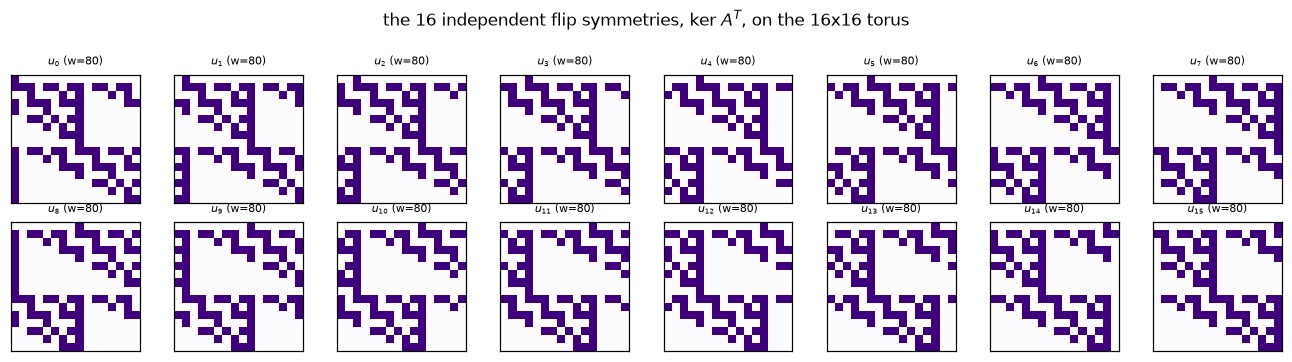

In [11]:
# render the symmetry generators
n = K_sym.shape[0]
ncols = 8
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(1.5 * ncols, 1.6 * nrows))
axes = np.atleast_1d(axes).ravel()
for i, ax_ in enumerate(axes):
    if i < n:
        ax_.imshow(K_sym[i].reshape(L, L), cmap="Purples", vmin=0, vmax=1,
                   interpolation="nearest", origin="lower")
        ax_.set_title(f"$u_{{{i}}}$ (w={int(K_sym[i].sum())})", fontsize=7)
    else:
        ax_.axis("off")
    ax_.set_xticks([]); ax_.set_yticks([])
fig.suptitle(f"the {n} independent flip symmetries, ker $A^T$, on the {L}x{L} torus", y=1.01)
plt.tight_layout(); plt.show()

L=32: N_c = 32


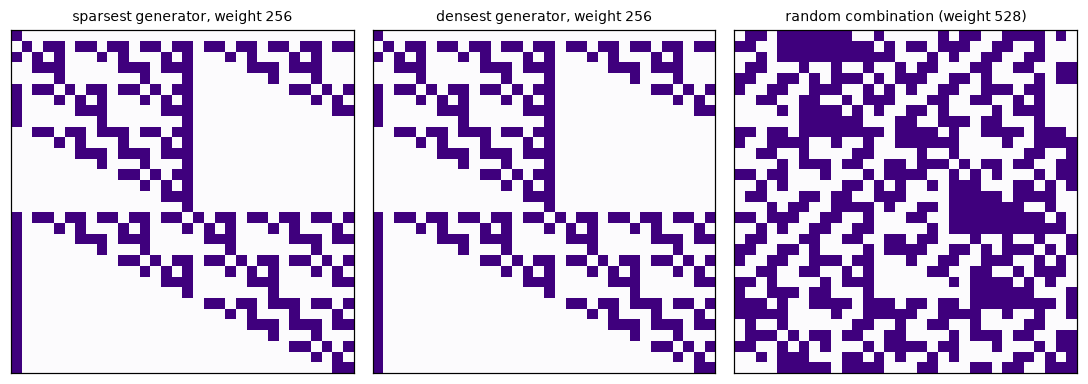

a random GF(2) combination is still a symmetry: True


In [12]:
# a single generator, on a torus where N_c is large: the fractal shape
L2 = 32
K2 = nullspace(build_matrix(TRI_T, L2, L2))
print(f"L={L2}: N_c = {K2.shape[0]}")

w = K2.sum(axis=1)
fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
for ax_, idx, lab in [(ax[0], int(np.argmin(w)), "sparsest"),
                      (ax[1], int(np.argmax(w)), "densest")]:
    ax_.imshow(K2[idx].reshape(L2, L2), cmap="Purples", vmin=0, vmax=1,
               interpolation="nearest", origin="lower")
    ax_.set_title(f"{lab} generator, weight {int(w[idx])}", fontsize=9)
    ax_.set_xticks([]); ax_.set_yticks([])

combo = (np.random.RandomState(0).randint(0, 2, K2.shape[0]) @ K2) % 2
ax[2].imshow(combo.reshape(L2, L2), cmap="Purples", vmin=0, vmax=1,
             interpolation="nearest", origin="lower")
ax[2].set_title(f"random combination (weight {int(combo.sum())})", fontsize=9)
ax[2].set_xticks([]); ax[2].set_yticks([])
plt.tight_layout(); plt.show()

AT2 = build_matrix(TRI_T, L2, L2)
print("a random GF(2) combination is still a symmetry:",
      not ((AT2 @ combo) % 2).any())

## 5. Why they are fractal: the stencil read as a cellular automaton

Solving $f=0$ for the topmost row gives the CA of the note's §2,

$$t_{r+1}=(1+x+x^2)\,t_r,$$

the direct analogue of Newman-Moore's $t_{r+1}=(1+x)t_r$ (Pascal mod 2 = Sierpinski).
On the torus the CA must close up on itself, and **the closed orbits are precisely the
kernel vectors** — which is why the generators above look like nested triangles.

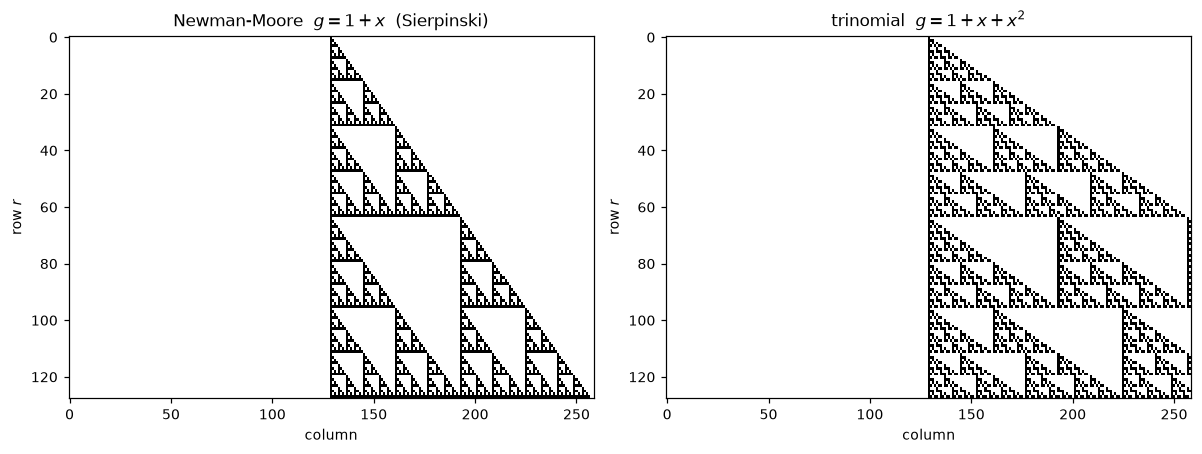

In [13]:
def ca_rows(nrows, g_exponents, width=None, seed_col=None):
    """Rows of t_{r+1} = g(x) t_r from a point seed, on an unbounded line."""
    width = width or 2 * nrows + 3
    seed_col = seed_col if seed_col is not None else width // 2
    out = np.zeros((nrows, width), dtype=np.uint8)
    row = np.zeros(width, dtype=np.uint8)
    row[seed_col] = 1
    for r in range(nrows):
        out[r] = row
        nxt = np.zeros(width, dtype=np.uint8)
        for e in g_exponents:
            if e:
                nxt[e:] ^= row[:width - e]
            else:
                nxt ^= row
        row = nxt
    return out

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for ax_, exps, ttl in [(ax[0], (0, 1), "Newman-Moore  $g=1+x$  (Sierpinski)"),
                       (ax[1], (0, 1, 2), "trinomial  $g=1+x+x^2$")]:
    R = ca_rows(128, exps)
    ax_.imshow(R, cmap="binary", interpolation="nearest", aspect="auto")
    ax_.set_title(ttl); ax_.set_xlabel("column"); ax_.set_ylabel("row $r$")
plt.tight_layout(); plt.show()

## 6. The fractal dimension — exactly, not fitted

The note reports a **log-log fit** of 1.6945 and flags the exact value as an open
thread (Willson's transfer-matrix method). That thread closes in elementary form.

**Setup.** Let $u_j$ be the bits of row $r$, $w(r)=\#\{j:u_j=1\}$, and
$a(r)=\#\{j:u_j=u_{j+1}=1\}$ the number of adjacent pairs. Frobenius in characteristic 2
gives $g(x)^{2r}=g(x^2)^r$, so row $2r$ is row $r$ with every exponent doubled, and row
$2r+1$ is that times $g(x)$. Writing out which cells survive:

$$\text{cell } 2j+1 \text{ of row } 2r+1 = u_j,\qquad
\text{cell } 2j \text{ of row } 2r+1 = u_j\oplus u_{j-1}$$

The even cell receives $x^{2e+2}$ from $e=j-1$ and $x^{2e}$ from $e=j$, and they cancel
when both are present — **this is exactly the cancellation the note's naive $T=3$
argument misses.** Counting:

$$w(2r)=w(r),\quad a(2r)=0,\quad w(2r+1)=3w(r)-2a(r),\quad a(2r+1)=2\big(w(r)-a(r)\big)$$

Summing over $r<2^n$ with $S_w(n)=\sum w$, $S_a(n)=\sum a$:

$$\begin{pmatrix}S_w\\S_a\end{pmatrix}_{n+1}
= M \begin{pmatrix}S_w\\S_a\end{pmatrix}_{n},\qquad
M=\begin{pmatrix}4&-2\\2&-2\end{pmatrix},\qquad
\lambda^2-2\lambda-4=0$$

$$\boxed{\;\lambda_{\max}=1+\sqrt5,\qquad
d_{\text{box}}=\log_2\!\big(1+\sqrt5\big)=1.694241913\ldots\;}$$

Note $1+\sqrt5=2\varphi$, so $d=1+\log_2\varphi$. The note's fitted 1.6945 is the
finite-size approximation to this.

Newman-Moore falls out of the same computation: with $g=1+x$ there is no even/odd
collision at all, $w(2r+1)=2w(r)$, $S_w(n+1)=3S_w(n)$, $d=\log_2 3$.

In [14]:
def w_a(row_mask):
    return bin(row_mask).count("1"), bin(row_mask & (row_mask >> 1)).count("1")

def next_row(row_mask):
    return row_mask ^ (row_mask << 1) ^ (row_mask << 2)      # multiply by 1+x+x^2

rows = {}
r_mask = 1
for r in range(4096):
    rows[r] = r_mask
    r_mask = next_row(r_mask)

# --- check the four local identities row by row ---------------------------
bad = []
for r in range(2048):
    w, a = w_a(rows[r])
    w2, a2 = w_a(rows[2 * r])
    w3, a3 = w_a(rows[2 * r + 1])
    if not (w2 == w and a2 == 0 and w3 == 3 * w - 2 * a and a3 == 2 * (w - a)):
        bad.append(r)
print("local identities  w(2r)=w(r),  a(2r)=0,  w(2r+1)=3w-2a,  a(2r+1)=2(w-a)")
print(f"  checked r < 2048 :  failures = {len(bad)}")

# --- the transfer matrix reproduces the sums -------------------------------
M = np.array([[4, -2], [2, -2]])
S = []
for n in range(1, 13):
    sw = sa = 0
    for r in range(2 ** n):
        w, a = w_a(rows[r]); sw += w; sa += a
    S.append((sw, sa))
ok = all(tuple(M @ np.array(S[i])) == S[i + 1] for i in range(len(S) - 1))
print("\n(S_w, S_a) and the transfer matrix:")
print("  M @ (S_w,S_a)_n == (S_w,S_a)_{n+1} for n=1..11 :", ok)
print("  S_w(n) =", [s[0] for s in S[:9]])

ev = np.sort(np.linalg.eigvals(M).real)[::-1]
print(f"\n  eigenvalues of M       : {ev}")
print(f"  lambda_max             : {ev[0]:.12f}")
print(f"  1 + sqrt(5)            : {1 + sqrt(5):.12f}")
print(f"  EXACT d = log2(1+sqrt5): {log2(1 + sqrt(5)):.9f}")

ns_fit = np.arange(4, 13)
ys = np.log2([S[n - 1][0] for n in ns_fit])
slope = np.polyfit(ns_fit, ys, 1)[0]
print(f"  the note log-log fit   : {slope:.4f}   (note reports 1.6945)")
print(f"  naive log2(1+T) = 2.0  -> wrong, as the note says")

local identities  w(2r)=w(r),  a(2r)=0,  w(2r+1)=3w-2a,  a(2r+1)=2(w-a)
  checked r < 2048 :  failures = 0

(S_w, S_a) and the transfer matrix:
  M @ (S_w,S_a)_n == (S_w,S_a)_{n+1} for n=1..11 : True
  S_w(n) = [4, 12, 40, 128, 416, 1344, 4352, 14080, 45568]

  eigenvalues of M       : [ 3.23606798 -1.23606798]
  lambda_max             : 3.236067977500
  1 + sqrt(5)            : 3.236067977500
  EXACT d = log2(1+sqrt5): 1.694241914
  the note log-log fit   : 1.6945   (note reports 1.6945)
  naive log2(1+T) = 2.0  -> wrong, as the note says


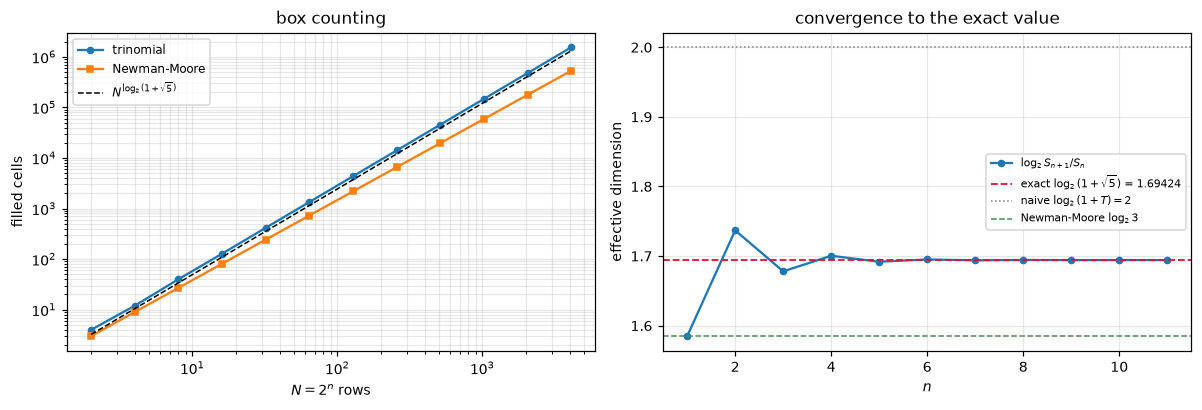

In [15]:
Sw_nm = [3 ** n for n in range(1, 13)]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

ns_ = np.arange(1, 13)
ax[0].loglog(2.0 ** ns_, [s[0] for s in S], "o-", ms=4, label="trinomial")
ax[0].loglog(2.0 ** ns_, Sw_nm, "s-", ms=4, label="Newman-Moore")
ax[0].loglog(2.0 ** ns_, (2.0 ** ns_) ** log2(1 + sqrt(5)), "k--", lw=1,
             label="$N^{\\log_2(1+\\sqrt{5})}$")
ax[0].set_xlabel("$N=2^n$ rows"); ax[0].set_ylabel("filled cells")
ax[0].set_title("box counting"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3, which="both")

eff = [log2(S[i + 1][0] / S[i][0]) for i in range(len(S) - 1)]
ax[1].plot(range(1, len(eff) + 1), eff, "o-", ms=4, label="$\\log_2 S_{n+1}/S_n$")
ax[1].axhline(log2(1 + sqrt(5)), color="crimson", ls="--", lw=1.2,
              label="exact $\\log_2(1+\\sqrt{5})$ = %.5f" % log2(1 + sqrt(5)))
ax[1].axhline(2.0, color="gray", ls=":", lw=1, label="naive $\\log_2(1+T)=2$")
ax[1].axhline(log2(3), color="#4d8c57", ls="--", lw=1, label="Newman-Moore $\\log_2 3$")
ax[1].set_xlabel("$n$"); ax[1].set_ylabel("effective dimension")
ax[1].set_title("convergence to the exact value")
ax[1].legend(fontsize=7); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

### Two quantities, deliberately kept apart

The note's §5 makes this point; worth re-stating now that both numbers are exact:

1. **How many** independent symmetry generators: $N_c\le L_x$ — *linear* in the side
   length, hence sub-extensive. A statement about the kernel's dimension.
2. **How big** one generator is: box-counting dimension $\log_2(1+\sqrt5)\approx1.694$ —
   a statement about a single generator's support.

Logically independent. Both must be checked separately for any new stencil.

## 7. Membranes: the symmetry operator is the *truncated* kernel vector

From [`docs/gsd_constraints_and_symmetries.md`](../docs/gsd_constraints_and_symmetries.md) §3:
a fully closed relation $\prod_p O_p^{t_p}=\mathbb 1$ is, taken literally, the identity —
not a symmetry operator. The physical membrane comes from **truncating** that relation
partway across the lattice; what survives at the cut is the generator.

The test: take $u\in\ker A^{\!\top}$ (so $A^{\!\top}u=0$ everywhere), zero it outside a
region, and look at where $A^{\!\top}u$ is now non-zero. If the truncation is a genuine
membrane, the violated terms live **only on the boundary of the cut** — the bulk stays
satisfied.

In [16]:
L = 24
AT = build_matrix(TRI_T, L, L)
K_sym = nullspace(AT)
u = K_sym[int(np.argmax(K_sym.sum(axis=1)))].reshape(L, L)      # a dense generator

def violations(patch):
    return ((AT @ patch.reshape(-1)) % 2).reshape(L, L)

cut = L // 2
half = u.copy(); half[:, cut:] = 0
box = np.zeros_like(u); box[4:16, 4:16] = u[4:16, 4:16]

v_full, v_half, v_box = violations(u), violations(half), violations(box)

print(f"closed generator          : {int(u.sum()):4d} cells, {int(v_full.sum()):3d} violated terms")
print(f"truncated to columns < {cut}  : {int(half.sum()):4d} cells, {int(v_half.sum()):3d} violated terms")
print(f"   violated columns       : {np.unique(np.argwhere(v_half)[:, 1])}")
print(f"truncated to a 12x12 box  : {int(box.sum()):4d} cells, {int(v_box.sum()):3d} violated terms")
print(f"   violated rows          : {np.unique(np.argwhere(v_box)[:, 0])}")
print(f"   violated cols          : {np.unique(np.argwhere(v_box)[:, 1])}")
print(f"\nfraction of the {L * L} terms violated by the half-cut: "
      f"{int(v_half.sum()) / (L * L):.3f}  -> boundary, not bulk")

closed generator          :  216 cells,   0 violated terms
truncated to columns < 12  :  108 cells,  66 violated terms
   violated columns       : [10 11 22 23]
truncated to a 12x12 box  :   53 cells,  38 violated terms
   violated rows          : [ 3  4  5  6  7  8  9 10 11 12 13 14 15]
   violated cols          : [ 2  3  4  6  7  8 10 11 12 14 15]

fraction of the 576 terms violated by the half-cut: 0.115  -> boundary, not bulk


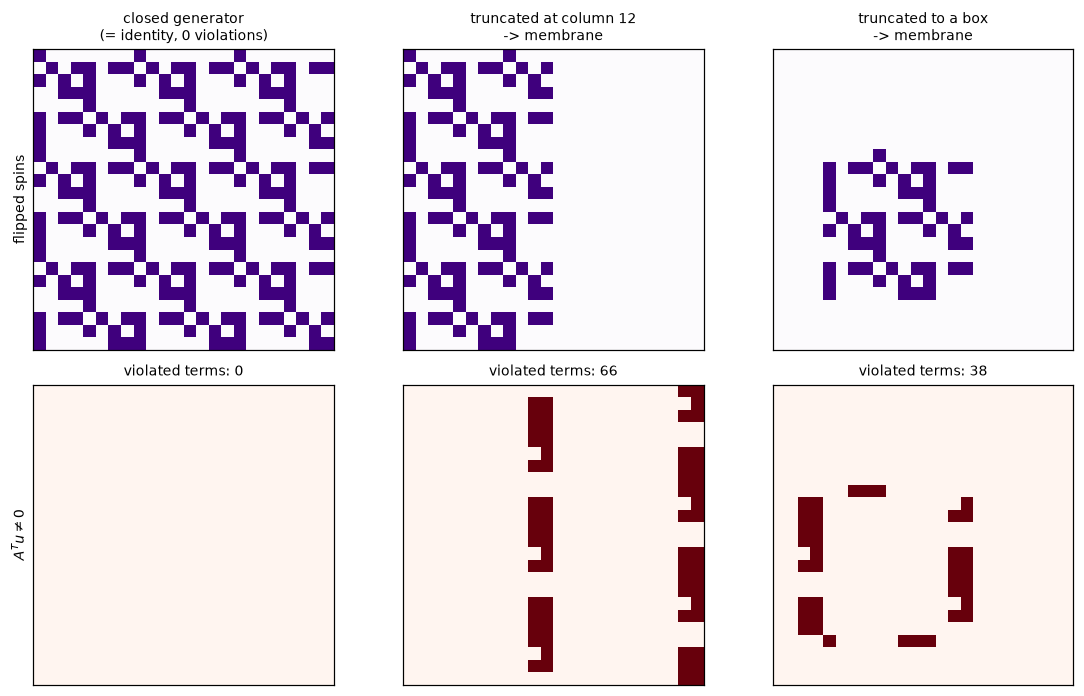

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.4))
for j, (patch, viol, ttl) in enumerate([
        (u, v_full, "closed generator\n(= identity, 0 violations)"),
        (half, v_half, f"truncated at column {cut}\n-> membrane"),
        (box, v_box, "truncated to a box\n-> membrane")]):
    axes[0, j].imshow(patch, cmap="Purples", vmin=0, vmax=1,
                      interpolation="nearest", origin="lower")
    axes[0, j].set_title(ttl, fontsize=9)
    axes[1, j].imshow(viol, cmap="Reds", vmin=0, vmax=1,
                      interpolation="nearest", origin="lower")
    axes[1, j].set_title(f"violated terms: {int(viol.sum())}", fontsize=9)
    for i in (0, 1):
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
axes[0, 0].set_ylabel("flipped spins", fontsize=9)
axes[1, 0].set_ylabel("$A^T u \\neq 0$", fontsize=9)
plt.tight_layout(); plt.show()

The violations hug the cut (and the periodic wrap), never the bulk. That is the defining
property of a membrane operator: it costs energy only at its boundary, and that boundary
cannot be contracted away — moving it costs the same energy again. This is the
**non-deformability** asserted in the working note's §3, made quantitative.

## 8. Restricted mobility

Flipping a pattern $u$ changes the syndrome by exactly $Au$, so mobility questions are
questions about $\operatorname{im}A$. Two *different* questions live here, and they have
different answers — the note's §4 conflates them slightly, and keeping them apart is
where the physics is.

**(i) Can a *local* operator move a defect?** Restrict $u$ to a $w\times w$ box and ask
whether $s=\delta_p+\delta_q$ lies in the span of those columns of $A$. This is an exact
test over **every** operator supported in that box — every weight, every shape — and so
strictly stronger than the note's weight-1-2, $7\times7$ search.

**(ii) Can *any* operator on the torus produce $s$?** Over GF(2),

$$s\in\operatorname{im}A\iff v^{\!\top}s=0\ \ \forall\,v\in\ker A^{\!\top},$$

so **each symmetry generator is a conserved charge** — a fractal-supported parity check
every excitation must satisfy. Kernel, symmetries and mobility are three readings of one
object.

The answers differ, and that difference *is* the fracton statement: (i) is always no,
while (ii) is sometimes yes — but only via an operator whose support is a finite fraction
of the whole torus. A wrapping membrane is not transport.

In [18]:
L = 20
A = build_matrix(TRI, L, L)
Q = nullspace(build_matrix(TRI_T, L, L))       # rows = conserved charges
N = L * L
print(f"L={L}: N_c = {Q.shape[0]} conserved charges")


def solve(Acols, s):
    """Solve Acols x = s over GF(2). Returns a solution, or None if inconsistent."""
    aug = np.concatenate([Acols, s.reshape(-1, 1)], axis=1) % 2
    R, piv = rref(aug)
    if Acols.shape[1] in piv:
        return None
    x = np.zeros(Acols.shape[1], dtype=np.uint8)
    for i, pc in enumerate(piv):
        x[pc] = R[i, -1]
    return x


def syndrome(sites):
    s = np.zeros(N, dtype=np.uint8)
    for (r, c) in sites:
        s[(r % L) * L + (c % L)] ^= 1
    return s


def local_solve(sites, w, centre=(10, 10)):
    """Any operator supported in a w x w box around `centre` producing this syndrome?"""
    r0, c0 = centre[0] - w // 2, centre[1] - w // 2
    cols = [((r0 + i) % L) * L + (c0 + j) % L for i in range(w) for j in range(w)]
    return solve(A[:, cols], syndrome(sites))


# Test 2 of the note: what does one spin flip create?
u = np.zeros((L, L), dtype=np.uint8); u[10, 10] = 1
cluster = [tuple(int(v) for v in p)
           for p in np.argwhere(((A @ u.reshape(-1)) % 2).reshape(L, L))]
print("\nTest 2 - flip a single spin at (10,10):")
print("   defects at", cluster)
print("   note reports [(10,10),(10,11),(10,12),(11,10)] ->",
      cluster == [(10, 10), (10, 11), (10, 12), (11, 10)])
print("   (this is the FORWARD stencil shape; the note calls it 'reversed' - see 9)")

L=20: N_c = 4 conserved charges

Test 2 - flip a single spin at (10,10):
   defects at [(10, 10), (10, 11), (10, 12), (11, 10)]
   note reports [(10,10),(10,11),(10,12),(11,10)] -> True
   (this is the FORWARD stencil shape; the note calls it 'reversed' - see 9)


In [19]:
print("(i) LOCAL operators: can any operator inside a w x w box hop one defect?\n")
print("    separation d, in each direction, box sizes w = 7, 11, 15")
print("    (the note searched weight 1-2 inside 7x7; this covers every weight/shape)\n")
for label, delta in [("horizontal", (0, 1)), ("vertical", (1, 0)), ("diagonal", (1, 1))]:
    row = []
    for d in range(1, 6):
        q = (10 + d * delta[0], 10 + d * delta[1])
        hit = any(local_solve([(10, 10), q], w) is not None for w in (7, 11, 15))
        row.append("yes" if hit else " . ")
    print(f"      {label:11s} d=1..5 : " + "  ".join(row))
print("\n    '.' = impossible.  No local operator of any shape moves a single defect.")

print("\n\n(ii) ANY operator on the torus: is the two-defect syndrome in im(A)?\n")
print(f"     {'L':>4} {'N_c':>5}   {'d=1':>10} {'d=2':>10} {'d=3':>10} {'d=4':>10}")
for LL in (16, 20, 24):
    Aq = build_matrix(TRI, LL, LL)
    NN = LL * LL
    nc = NN - len(rref(Aq)[1])
    out = []
    for d in range(1, 5):
        s = np.zeros(NN, dtype=np.uint8)
        s[10 * LL + 10] ^= 1
        s[10 * LL + (10 + d) % LL] ^= 1
        x = solve(Aq, s)
        out.append("-" if x is None else f"w={int(x.sum())}/{NN}")
    print(f"     {LL:>4} {nc:>5}   " + " ".join(f"{o:>10}" for o in out))
print("\n     '-' = impossible even globally.  Where it IS possible the operator has")
print("     weight ~N/2: an extensive, torus-wrapping membrane, not a string.")
print("     Which tori allow it is itself set by the arithmetic of L (via N_c).")

(i) LOCAL operators: can any operator inside a w x w box hop one defect?

    separation d, in each direction, box sizes w = 7, 11, 15
    (the note searched weight 1-2 inside 7x7; this covers every weight/shape)

      horizontal  d=1..5 :  .    .    .    .    . 
      vertical    d=1..5 :  .    .    .    .    . 
      diagonal    d=1..5 :  .    .    .    .    . 

    '.' = impossible.  No local operator of any shape moves a single defect.


(ii) ANY operator on the torus: is the two-defect syndrome in im(A)?

        L   N_c          d=1        d=2        d=3        d=4
       16    16            -          -          -          -
       20     4            -          -          -  w=176/400


       24     8            -          -          -          -

     '-' = impossible even globally.  Where it IS possible the operator has
     weight ~N/2: an extensive, torus-wrapping membrane, not a string.
     Which tori allow it is itself set by the arithmetic of L (via N_c).


In [20]:
print("Test 1 - straight string operators (8 flips in a line)\n")
for shifts, nm in [(DW, "control  f = 1 + x"), (TRI, "trinomial"), (NM, "newman-moore")]:
    Am = build_matrix(shifts, L, L)
    row = []
    for orient in ("horizontal", "vertical"):
        u_ = np.zeros((L, L), dtype=np.uint8)
        for k in range(8):
            if orient == "horizontal":
                u_[10, 10 + k] = 1
            else:
                u_[10 + k, 10] = 1
        row.append(int(((Am @ u_.reshape(-1)) % 2).sum()))
    print(f"  {nm:20s}: horizontal {row[0]:3d} defects, vertical {row[1]:3d} defects")
print("\n  note reports: control 2 (clean endpoints), trinomial 16 / 18  -> reproduced")
print("  (the control f=1+x is a domain wall along x only, so its vertical string")
print("   is not the mobile direction - the horizontal 2 is the meaningful entry)")

# for the control, a defect pair IS locally creatable at every separation
Adw = build_matrix(DW, L, L)
def local_dw(d, w=11):
    r0, c0 = 10 - w // 2, 10 - w // 2
    cols = [((r0 + i) % L) * L + (c0 + j) % L for i in range(w) for j in range(w)]
    s = np.zeros(N, dtype=np.uint8); s[10 * L + 10] ^= 1; s[10 * L + 10 + d] ^= 1
    return solve(Adw[:, cols], s) is not None
print("\n  control f=1+x, pair at separation d creatable by a LOCAL operator:",
      [d for d in range(1, 6) if local_dw(d)], "-> MOBILE (a genuine string operator)")

Test 1 - straight string operators (8 flips in a line)

  control  f = 1 + x  : horizontal   2 defects, vertical  16 defects
  trinomial           : horizontal  16 defects, vertical  18 defects
  newman-moore        : horizontal  10 defects, vertical  10 defects

  note reports: control 2 (clean endpoints), trinomial 16 / 18  -> reproduced
  (the control f=1+x is a domain wall along x only, so its vertical string
   is not the mobile direction - the horizontal 2 is the meaningful entry)

  control f=1+x, pair at separation d creatable by a LOCAL operator: [1, 2, 3, 4, 5] -> MOBILE (a genuine string operator)


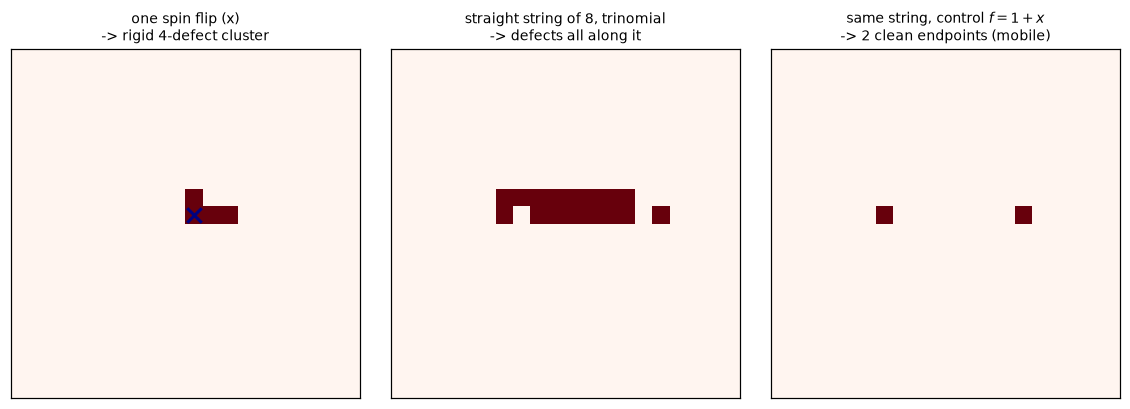

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.6))
u_ = np.zeros((L, L), dtype=np.uint8); u_[10, 10] = 1
ax[0].imshow(((A @ u_.reshape(-1)) % 2).reshape(L, L), cmap="Reds", vmin=0, vmax=1,
             interpolation="nearest", origin="lower")
ax[0].scatter([10], [10], marker="x", s=90, c="navy", lw=2)
ax[0].set_title("one spin flip (x)\n-> rigid 4-defect cluster", fontsize=9)

u_ = np.zeros((L, L), dtype=np.uint8); u_[10, 6:14] = 1
ax[1].imshow(((A @ u_.reshape(-1)) % 2).reshape(L, L), cmap="Reds", vmin=0, vmax=1,
             interpolation="nearest", origin="lower")
ax[1].set_title("straight string of 8, trinomial\n-> defects all along it", fontsize=9)

Adw = build_matrix(DW, L, L)
ax[2].imshow(((Adw @ u_.reshape(-1)) % 2).reshape(L, L), cmap="Reds", vmin=0, vmax=1,
             interpolation="nearest", origin="lower")
ax[2].set_title("same string, control $f=1+x$\n-> 2 clean endpoints (mobile)", fontsize=9)
for a_ in ax:
    a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.show()

**Conclusion.** No local operator — of any weight or shape, in boxes up to $15\times15$ —
moves a defect by any distance in any direction. The elementary excitation is the rigid
4-point cluster of Test 2, and it is permanently bound: not merely beyond the reach of a
$7\times7$ weight-2 search, as the note establishes, but beyond *every* bounded operator.

Globally the picture is more interesting than "impossible". On some tori a separated pair
*is* in $\operatorname{im}A$ — but only via an operator of weight $\sim N/2$, an extensive
wrapping membrane of the kind built in §7, and *which* tori allow it is decided by the
same arithmetic that sets $N_c$. That is restricted mobility in its sharp form: charges
move only by the fractal, non-deformable operators that generate the symmetry group, and
the control $f=1+x$ — where a genuine local string operator exists at every separation —
shows what the mobile alternative looks like.

## 9. Corrections and additions to the working note

Reproduced exactly: the $N_c$ table (§2), the `haah_z` $32\times32\to63$ sanity check,
the mobility counts 16 / 18 / 2 (§4), the 4-point cluster coordinates (§4), the
Newman-Moore dimension 1.5850 (§5), and the observation that the naive $\log_2(1+T)=2$
prediction fails.

| # | Note says | Correction |
|---|---|---|
| 1 | §2 closed form uses $g(x)^{m_x}+1$ against $y^{m_y}+1$ | exponent should be $m_y$, in one variable: $\deg\gcd_{\mathbb F_2[x]}(x^{m_x}+1,\,g(x)^{m_y}+1)$. Invisible on square tori; **446/529** vs **529/529** on the rectangular grid $2\le L_x,L_y\le24$ |
| 2 | §2 "**extensive** growth at powers of 2" | growth is linear in the side length, hence **sub-extensive**. Extensive would mean $\propto L_xL_y$ |
| 3 | §4 Test 2, the 4-cluster is "the **reversed** stencil stamped down" | the listed coordinates are right, but that shape is the **forward** stencil. With $A$'s column $k$ = stencil stamped at site $k$, one flip creates $A\delta_k$ = forward shape; the *reversed* stencil is what generates the symmetries $\ker A^{\!\top}$ |

**Additions.**

* **§5 open thread closed.** The fractal dimension is exactly
  $d=\log_2(1+\sqrt5)=1+\log_2\varphi=1.694241913\ldots$, from the $2\times2$ transfer
  matrix $M=\left(\begin{smallmatrix}4&-2\\2&-2\end{smallmatrix}\right)$ acting on
  $(S_w,S_a)$ = (cells, adjacent pairs). The note's fitted 1.6945 is the finite-size
  approximation. No Willson machinery needed: the only cancellation is between $x^{2e+2}$
  and $x^{2e}$ from adjacent set bits, which is exactly what the $a(r)$ bookkeeping tracks.
* **§6 open thread (the "$3\mid\gcd$" analog) resolved.** Since $g=\Phi_3$, having
  $3\mid m_x$ *removes* the two points $\omega,\omega^2$ rather than adding them — the
  criterion inverts relative to `haah_z`. The maximal family is $m=2^k-1$, giving
  $N(m,m)=m-2[k\text{ even}]$ and $N_c\approx L$, half of `haah_z`'s $\approx2L$ because
  there is one branch instead of a split conic's two.
* **Bound:** $N_c\le L_x$ — *asymmetric*, since $f$ has degree 2 in $x$ but 1 in $y$, so
  $N_c(L_x,L_y)\neq N_c(L_y,L_x)$ in general (e.g. $N_c(15,3)=5$ but $N_c(3,15)=1$).
  Compare the primer's symmetric $N_c\le2\min(L_x,L_y)$ for `haah_z`.
* **Mobility sharpened, and split in two.** Locally: no operator of *any* weight or shape
  in a box up to $15\times15$ hops a defect — strictly stronger than the note's weight-2
  $7\times7$ search. Globally: some separated pairs *are* in $\operatorname{im}A$, but
  only via extensive ($\sim N/2$) wrapping membranes, and only on tori whose arithmetic
  allows it. The note's blanket "no solution exists" is right for local operators and too
  strong for global ones.

### Still open

* Add the cross term, $f=1+x+x^2+y+xy$, to force a genuine nodal point and put this
  family under primer Theorem 13.1 rather than the Newman-Moore branch (note §6).
* Classify mobility of *fractal-shaped* operators, not just straight strings — the local
  solve above is the right tool: sweep the region shape, not just its size.
* Compare with Haah's genuine 3D cubic code, where point-like fractons appear natively.